In [1]:
from auxillaryFunctions import *
from scipy.signal import welch

np.random.seed(0)

build_dir,configType = "build", "Release" #"Debug" Release ##NOTE: make sure your are using correct version
moduleDir = os.path.join(build_dir, configType)
if moduleDir not in sys.path:
    sys.path.append(moduleDir)

import cathalTest

def solveSystemCpp(ac,TS,runTime,samplingInterval=2,stimInfoSpikes={},stimInfoCurrents = {}, 
                   recordingKeys = ["voltages","calciumVals","netCurrent","current"],singleThread=False):
    nIterations = int(runTime/TS)
    nSamples = int(np.ceil(nIterations/samplingInterval))
    spikeStimTimes,spikeStimNeurons = genSpikeStimArrays(stimInfoSpikes)
    ac["spikeStimTimes"] = spikeStimTimes
    ac["spikeStimNeurons"] = spikeStimNeurons

    biasStimTimes,biasStimSegments,biasStimValues = genBiasStimArrays(stimInfoCurrents)
    ac["biasStimTimes"] = biasStimTimes
    ac["biasStimSegments"] = biasStimSegments
    ac["biasStimValues"] = biasStimValues
    ac["performanceStats"] = np.zeros(8,dtype=np.float32)


    recordingData = {}
    for key in recordingKeys:
        shape = [nSamples] + list(ac[key].shape)
        recordingData[key] = np.zeros(shape,dtype=np.float32) #np.ascontiguousarray

    tv = np.linspace(0,runTime,nSamples)

    if singleThread:
        cathalTest.solveNeuralSystemSingleThread(ac,recordingData,TS,nIterations,samplingInterval)
    else:
        cathalTest.solveNeuralSystem(ac,recordingData,TS,nIterations,samplingInterval)
    
    #trackPerfOverTime(ac)
    recordingData["time"] = tv
    return recordingData

def getCorrectSpikerOutput(data):
    #"spikes" as recorded can last for more than one iteration because its just Vm>0 
    deriv = np.diff(data["spikerOutput"],axis=0)>0
    deriv = np.pad(deriv, ((1, 0), (0, 0)), mode='constant')
    return deriv

def getPopSpikeTrains(simData,data):
    correctOp = getCorrectSpikerOutput(data)

    spikeTimes = [[] for i in range(data["spikerOutput"].shape[1])]
    for timeInd,neurInd in zip(*np.where(correctOp)):
        spikeTimes[neurInd].append(float(data["time"][timeInd]))

    indices = {}
    for popName,popDict in  simData["indexMaps"]["neuronPopToSpikerMap"].items():
        indices[popName] = list(popDict.values())

    spikeTimeDict = {}
    for pop,inds in indices.items():
        spikeTimeDict[pop] = [spikeTimes[i] for i in inds]

    return spikeTimeDict


In [12]:
def getCaVWeight(CTXweight,runTime = 2_000):
    np.random.seed(0)

    STNchannels = np.load(os.path.join("tools","translatedSTNchannels2.npy"),allow_pickle=True).item()
    GPechannels = np.load(os.path.join("tools","translatedGPechannels2.npy"),allow_pickle=True).item()


    STNbias = -2.05
    GPeBias = -0.55

    TS = 0.04


    CTXrate,GPerate = 3.3,30 #3.3,2.1

    bestRes = [0.06,0.025,0.01,0.005,0.27115]
    # wCTXToSTN =  CTXweight #have to reduce this in order to reduce STN firing rates in this scenario
    wGPeToSTN = bestRes[2]
    coupling,nSegments = 0.25,1 #try with one segment
    STNDendriteMap = [(i+1,0,coupling) for i in range(nSegments)]
    STNDendriteInfo = [{"channels":STNchannels,"bias":STNbias,"CaEquilibriumVal":0,
                                "CaRemovalRate":2} for _ in range(nSegments)]
    STNNeurons = [Neuron(i,"STN","excitatory",AISchannels=STNchannels,AISbias=STNbias,denderiteInfo=STNDendriteInfo,dendriteMap=STNDendriteMap) for i in range(1)]

    nCTX = nGPe = 1
    CTXSpikers = [Spiker(i,"CTX","excitatory",CTXrate,TS) for i in range(nCTX)]
    GPeSpikers = [Spiker(i,"GPe","inhibitory",GPerate,TS) for i in range(nGPe)]

    neuronDict = {"STN":STNNeurons}
    spikerDict = {"CTX":CTXSpikers} #,"GPe":GPeSpikers}

    seg = 1 #target the first dendritic segment, not the soma (though we can try that)
    CSEL = [[i,0,seg] for i in range(nCTX)]
    GSEL = [[i,0,seg] for i in range(nGPe)]

    CSplasticityParameters = {
        "efficacy": 0, #p, unitless
        "conductanceGain": 0, #
        "rate": 0*3.3e-5, #ms
        "gammaP": 0.1, #p per ms above thetaP 
        "gammaD": 0.01, #p per ms abover thetaD
        "thetaP": 0.75e-5, #Ca mol/L
        "thetaD": 0.55e-5, #Ca mol/L
    }

    CSexcSynapses = {"AMPA":genAMPA(TS,CTXweight,**CSplasticityParameters),
                        "NMDA_ion":genNMDA_ion(TS,CTXweight,conductanceGain=0),
                        "NMDA_Ca":genNMDA_Ca(TS,CTXweight,conductanceGain=0)}

    GSInhSynapses = {"GABA":genGABA(TS,wGPeToSTN,conductanceGain=0)}

    CTXToSTNSynapses = createSynapses(CTXSpikers,STNNeurons,None,CTXweight,0.2,TS,synapses=CSexcSynapses,edgeList=CSEL)
    # GPeToSTNSynapses = createSynapses(GPeSpikers,STNNeurons,None,wGPeToSTN,4,TS,synapses=GSInhSynapses,edgeList=GSEL)

    synapseDict = {"CTXToSTN":CTXToSTNSynapses} #,"GPeToSTN":GPeToSTNSynapses}

    simData = genSimData(neuronDict,spikerDict,synapseDict,TS)

    
    stimInfoSpikes,stimInfoCurrents = {},{}
    simDataCpp = deepcopy(simData)
    simDataCpp["debugRecording"] = np.zeros_like(simDataCpp["current"])
    dataCpp = solveSystemCpp(simDataCpp,TS,runTime,samplingInterval=1,stimInfoSpikes=stimInfoSpikes,
                            recordingKeys =["spikerOutput","voltages","calciumVals","efficacy"],singleThread=True)

    spikeTimeDict = getPopSpikeTrains(simDataCpp,dataCpp)

    return dataCpp, spikeTimeDict,simData

dataCpp, spikeTimeDict, simData = getCaVWeight(0.06)

Elapsed time in seconds: 0.083124166


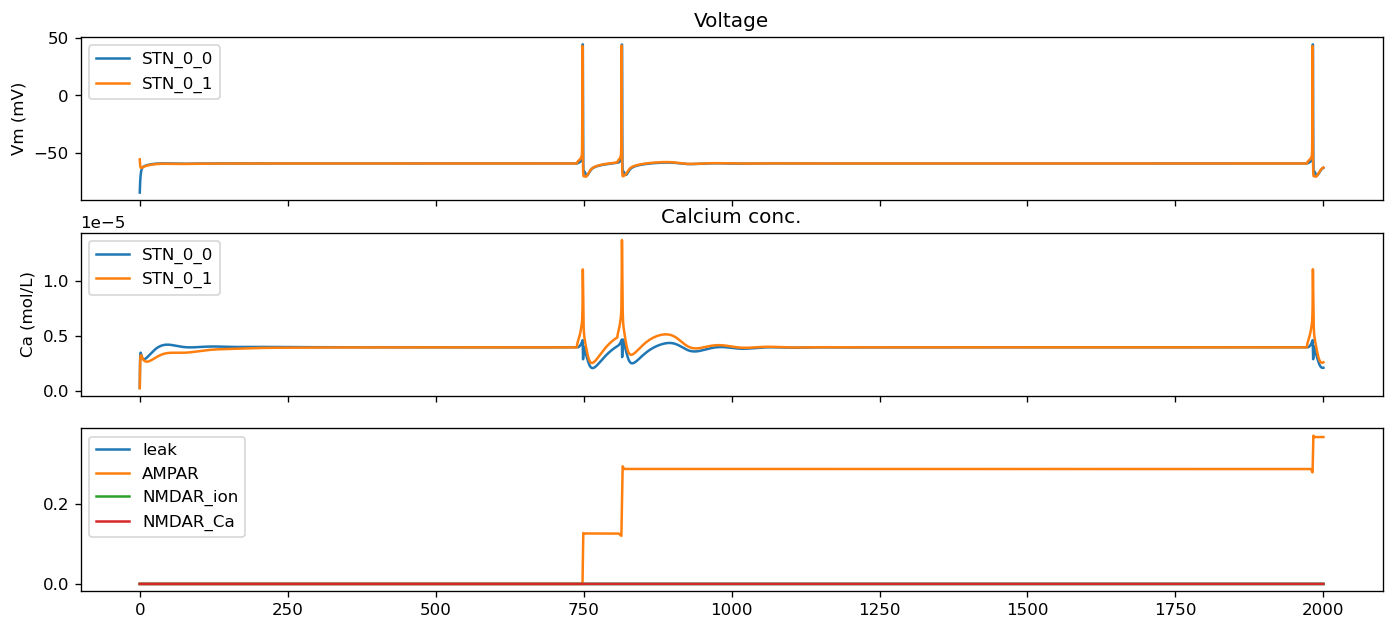

In [ ]:
V = dataCpp["voltages"]
Ca = dataCpp["calciumVals"]
p = dataCpp["efficacy"]
tv = dataCpp["time"]
fig,ax = plt.subplots(3,1,figsize=(14,6),sharex=True,dpi=120)
ax[0].plot(tv,V,label = simData["neuronName"])
ax[0].set_title("Voltage")
ax[0].set_ylabel("Vm (mV)")
ax[1].plot(tv,Ca,label = simData["neuronName"])
ax[1].set_title("Calcium conc.")
ax[1].set_ylabel("Ca (mol/L)")
ax[2].plot(tv,p[:,-4::],label = simData["channelName"][-4::]);
for a in ax:
    a.legend()  

# if the rate is 0 why are these ampar synapses getting stronger

In [ ]:

np.random.seed(0)

STNchannels = np.load(os.path.join("tools","translatedSTNchannels2.npy"),allow_pickle=True).item()
GPechannels = np.load(os.path.join("tools","translatedGPechannels2.npy"),allow_pickle=True).item()


STNbias = -2.05
GPeBias = -0.55

TS = 0.04


CTXrate,GPerate = 3.3,30 #3.3,2.1

bestRes = [0.06,0.025,0.01,0.005,0.27115]
wCTXToSTN =  bestRes[0]*0.11 #have to reduce this in order to reduce STN firing rates in this scenario
wSTNToGPe =  bestRes[1]
wGPeToSTN = bestRes[2]*5 #increase to get accurate STN rates
wGPeToGPe = bestRes[3]
wMSNToGPe =  bestRes[4]

#NOTE: for investigating plasticity we want to set up a little simulation 
# with a couple of pre-synaptic CTX neurons and a post synaptic STN neuron
#Then we adjust parameters until we get something stable in the single cell
#Then we try with a population and adjust until we get something stable 
# Need to do this for excitatory and inhibitory synapses, lets start with STN

coupling,nSegments = 0.25,1 #try with one segment
STNDendriteMap = [(i+1,0,coupling) for i in range(nSegments)]
STNDendriteInfo = [{"channels":STNchannels,"bias":STNbias,"CaEquilibriumVal":0,
                            "CaRemovalRate":2} for _ in range(nSegments)]
STNNeurons = [Neuron(i,"STN","excitatory",AISchannels=STNchannels,AISbias=STNbias,denderiteInfo=STNDendriteInfo,dendriteMap=STNDendriteMap) for i in range(1)]

nCTX = nGPe = 10
CTXSpikers = [Spiker(i,"CTX","excitatory",CTXrate,TS) for i in range(nCTX)]
GPeSpikers = [Spiker(i,"GPe","inhibitory",GPerate,TS) for i in range(nGPe)]

neuronDict = {"STN":STNNeurons}
spikerDict = {"CTX":CTXSpikers,"GPe":GPeSpikers}

seg = 1 #target the first dendritic segment, not the soma (though we can try that)
CSEL = [[i,0,seg] for i in range(nCTX)]
GSEL = [[i,0,seg] for i in range(nGPe)]


CSplasticityParameters = {
        "efficacy": 0, #p, unitless
        "conductanceGain": 0, #
        "rate": 3.3e-5, #ms
        "gammaP": 0.1, #p per ms above thetaP 
        "gammaD": 0.01, #p per ms abover thetaD
        "thetaP": 0.75e-5, #Ca mol/L
        "thetaD": 0.55e-5, #Ca mol/L
    }

CSexcSynapses = {"AMPA":genAMPA(TS,wCTXToSTN,**CSplasticityParameters),
                    "NMDA_ion":genNMDA_ion(TS,wCTXToSTN,conductanceGain=0),
                    "NMDA_Ca":genNMDA_Ca(TS,wCTXToSTN,conductanceGain=0)}

GSInhSynapses = {"GABA":genGABA(TS,wGPeToSTN,conductanceGain=0)}

CTXToSTNSynapses = createSynapses(CTXSpikers,STNNeurons,None,wCTXToSTN,0.2,TS,synapses=CSexcSynapses,edgeList=CSEL)
GPeToSTNSynapses = createSynapses(GPeSpikers,STNNeurons,None,wGPeToSTN,4,TS,synapses=GSInhSynapses,edgeList=GSEL)

synapseDict = {"CTXToSTN":CTXToSTNSynapses,"GPeToSTN":GPeToSTNSynapses}

simData = genSimData(neuronDict,spikerDict,synapseDict,TS)
print(f"Total number of channels {simData['nChannels']}")

Total number of channels 54


In [81]:
#Make sure everything is set up properly
#STN should have 10 random cortical inputs at 3.3Hz, and should spike at 10Hz
#If you have random GPe spikers, you dont get the same firing rate in the STN as you do in the real network. 
#Correlated interactions alter the firing pattern.
#This altered firing pattern is DEFINITELY going to affect plasticity so this whole approach is kind of pointless, other than to get a sense of parameters
#Actual tuning will require using the full network, all at once
#Structural plasticity will further alter things on top of this
#Found the average value of weights for the system, each set of synapses should have a mean efficacy of like 0.33, though it will be bimodal

In [ ]:
runTime = 10_000

stimInfoSpikes,stimInfoCurrents = {},{}
simDataCpp = deepcopy(simData)
simDataCpp["debugRecording"] = np.zeros_like(simDataCpp["current"])
dataCpp = solveSystemCpp(simDataCpp,TS,runTime,samplingInterval=1,stimInfoSpikes=stimInfoSpikes,
                        recordingKeys =["spikerOutput","voltages","calciumVals","efficacy"],singleThread=True)

spikeTimeDict = getPopSpikeTrains(simDataCpp,dataCpp)

firingRates = {}
for pop,data in spikeTimeDict.items():
    firingRates[pop] = (1e3/runTime)* np.array([len(x) for x in data])

for pop,rates in firingRates.items():
    print(pop,np.mean(rates))

# on mac, 10_000 ms runs is 0.46 seconds

Elapsed time in seconds: 0.46462362500000004
STN 2.0
CTX 2.98
GPe 30.18


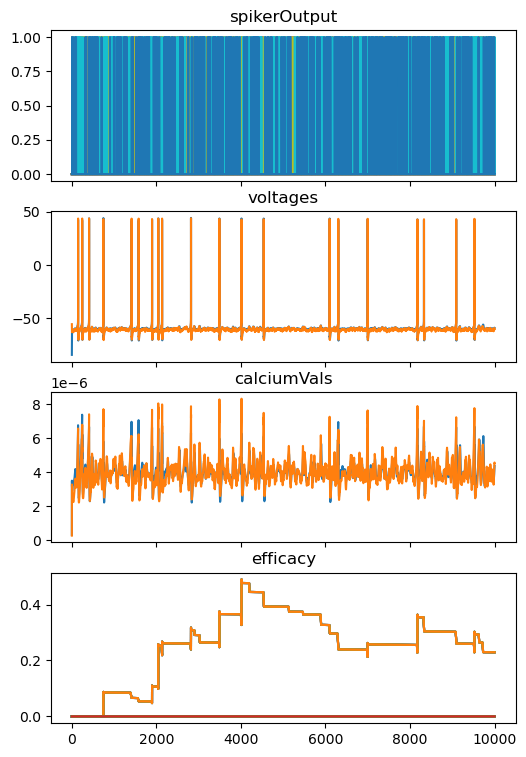

In [4]:
#TODO: better plotting
keysToPlot = ["spikerOutput","voltages","calciumVals","efficacy", "time"]
standardPlot({key:dataCpp[key] for key in keysToPlot})

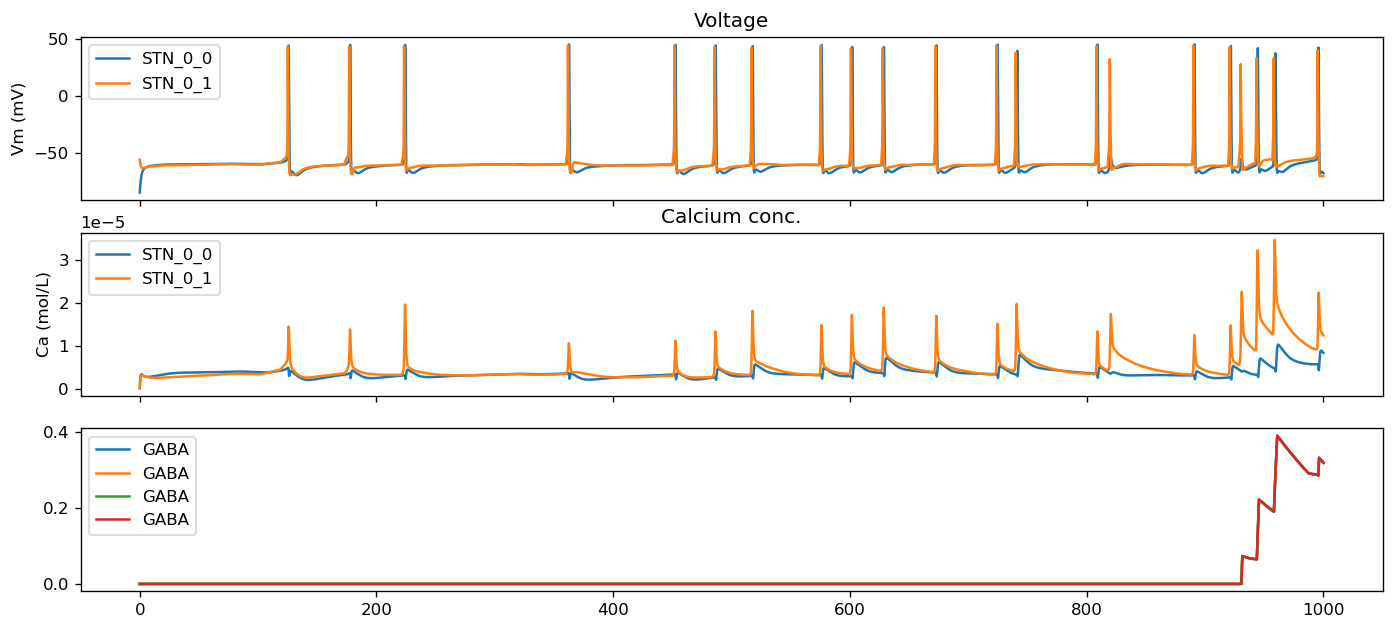

In [37]:
V = dataCpp["voltages"]
Ca = dataCpp["calciumVals"]
p = dataCpp["efficacy"]
tv = dataCpp["time"]
fig,ax = plt.subplots(3,1,figsize=(14,6),sharex=True,dpi=120)
ax[0].plot(tv,V,label = simData["neuronName"])
ax[0].set_title("Voltage")
ax[0].set_ylabel("Vm (mV)")
ax[1].plot(tv,Ca,label = simData["neuronName"])
ax[1].set_title("Calcium conc.")
ax[1].set_ylabel("Ca (mol/L)")
ax[2].plot(tv,p[:,-4::],label = simData["channelName"][-4::]);
for a in ax:
    a.legend()  

In [ ]:
def standardPlot(data,ax=None,ls="-"):
    if ax is None:
        fig,ax = plt.subplots(len(data.keys())-1,1,figsize=(6,1.8*len(data.keys())),dpi=100,sharex=True)
    time = data["time"]
    if type(ax) is not np.ndarray:
        ax = [ax]
    for i,(key,val) in enumerate(data.items()):
        if key != "time":
            ax[i].set_title(key)
            if len(val.shape)<3:
                ax[i].plot(time,val,ls=ls)
            else:
                ax[i].plot(time,val.sum(axis=2),ls=ls)


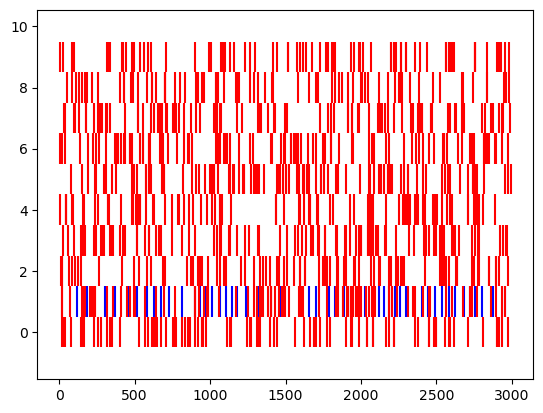

In [10]:


spikeTimeDict = getPopSpikeTrains(simDataCpp,dataCpp)
fig,ax = plt.subplots(1,1)
ax.eventplot(spikeTimeDict["STN"],color="b");
ax.eventplot(spikeTimeDict["GPe"],color="r");